# Análise das reclamações

## Reclamações por semana

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# Camada ouro gerada pelo pipeline (python -m pipeline.executar --sem-coleta)
df = pd.read_parquet("data/ouro/reclamacoes.parquet")
df.shape

(99, 6)

In [9]:
# Semanas de segunda a domingo ("W-SUN" = semana que termina no domingo).
# resample também cria semanas sem reclamações, com contagem 0.
por_semana = df.set_index("Data").resample("W-SUN").size().rename("quantidade").to_frame()
por_semana["fim"] = por_semana.index
por_semana["inicio"] = por_semana["fim"] - pd.Timedelta(days=6)
por_semana["rotulo"] = (
    por_semana["inicio"].dt.strftime("%d/%m") + " – " + por_semana["fim"].dt.strftime("%d/%m")
)

# Semana parcial: o período dos dados começa ou termina no meio dela.
primeiro_dia, ultimo_dia = df["Data"].min(), df["Data"].max()
por_semana["parcial"] = (por_semana["inicio"] < primeiro_dia) | (por_semana["fim"] > ultimo_dia)

por_semana.reset_index(drop=True)

,quantidade,fim,inicio,rotulo,parcial
0,6,2026-08-30,2026-08-24,24/08 – 30/08,True
1,22,2026-09-06,2026-08-31,31/08 – 06/09,False
2,24,2026-09-13,2026-09-07,07/09 – 13/09,False
3,28,2026-09-20,2026-09-14,14/09 – 20/09,False
4,19,2026-09-27,2026-09-21,21/09 – 27/09,True


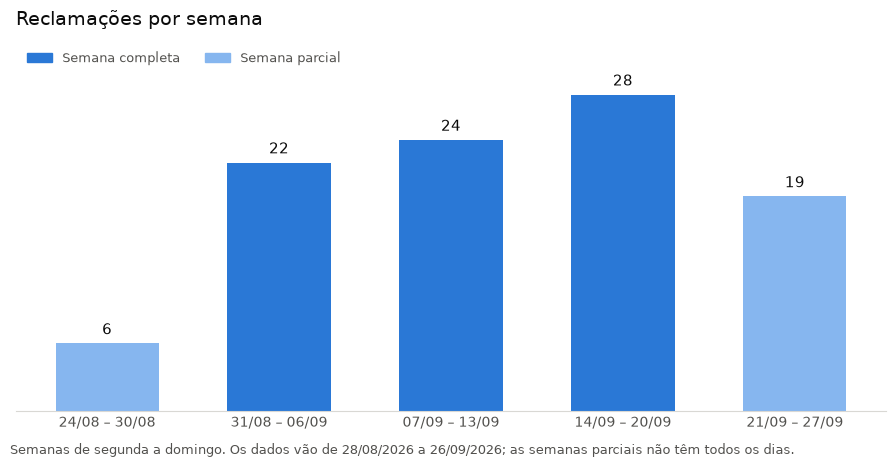

In [10]:
COR_BARRA = "#2a78d6"      # semana completa
COR_PARCIAL = "#86b6ef"    # semana parcial (mesmo tom, mais claro)
COR_TEXTO = "#0b0b0b"
COR_TEXTO_SEC = "#52514e"
COR_EIXO = "#d9d8d4"

fig, ax = plt.subplots(figsize=(9, 4.5))
cores = por_semana["parcial"].map({False: COR_BARRA, True: COR_PARCIAL})
barras = ax.bar(por_semana["rotulo"], por_semana["quantidade"], width=0.6, color=cores)

# Poucas barras: o valor no topo de cada uma substitui o eixo Y.
ax.bar_label(barras, padding=4, color=COR_TEXTO, fontsize=11)
ax.set_yticks([])
ax.set_ylim(0, por_semana["quantidade"].max() * 1.15)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color(COR_EIXO)
ax.tick_params(axis="x", length=0, colors=COR_TEXTO_SEC, labelsize=10)

ax.set_title("Reclamações por semana", loc="left", color=COR_TEXTO, fontsize=14, pad=16)

if por_semana["parcial"].any():
    from matplotlib.patches import Patch
    ax.legend(
        handles=[Patch(color=COR_BARRA, label="Semana completa"),
                 Patch(color=COR_PARCIAL, label="Semana parcial")],
        loc="upper left", bbox_to_anchor=(0, 1.02), ncol=2, frameon=False,
        fontsize=9, labelcolor=COR_TEXTO_SEC,
    )
    fig.text(
        0.01, -0.02,
        f"Semanas de segunda a domingo. Os dados vão de {primeiro_dia:%d/%m/%Y} a {ultimo_dia:%d/%m/%Y}; "
        "as semanas parciais não têm todos os dias.",
        fontsize=9, color=COR_TEXTO_SEC,
    )

fig.tight_layout()
plt.show()